## Szkieletyzacja (skeletonization)

Szkieletyzacja polega na stopniowym usuwaniu pikseli z krawędzi obiektu, aż pozostanie jego szkielet — cienka linia biegnąca wzdłuż „środka” obiektu.
Szkielet zachowuje:
* kształt (ogólny zarys),
* topologię (połączenia między częściami),
* długość i układ rozgałęzień.

Piksele z brzegu obiektu są usuwane iteracyjnie, ale tylko wtedy, gdy:
* nie naruszają spójności obiektu,
* nie rozdzielają go na kilka części.

## Pocienianie (thinning)

Pocienianie to proces redukcji szerokości obiektu binarnego do linii o grubości jednego piksela, **bez koniecznego zachowania osi symetrii** jak w szkieletyzacji.
Działa poprzez stopniowe „ścienianie” kształtu z krawędzi, aż obiekt stanie się maksymalnie cienki.

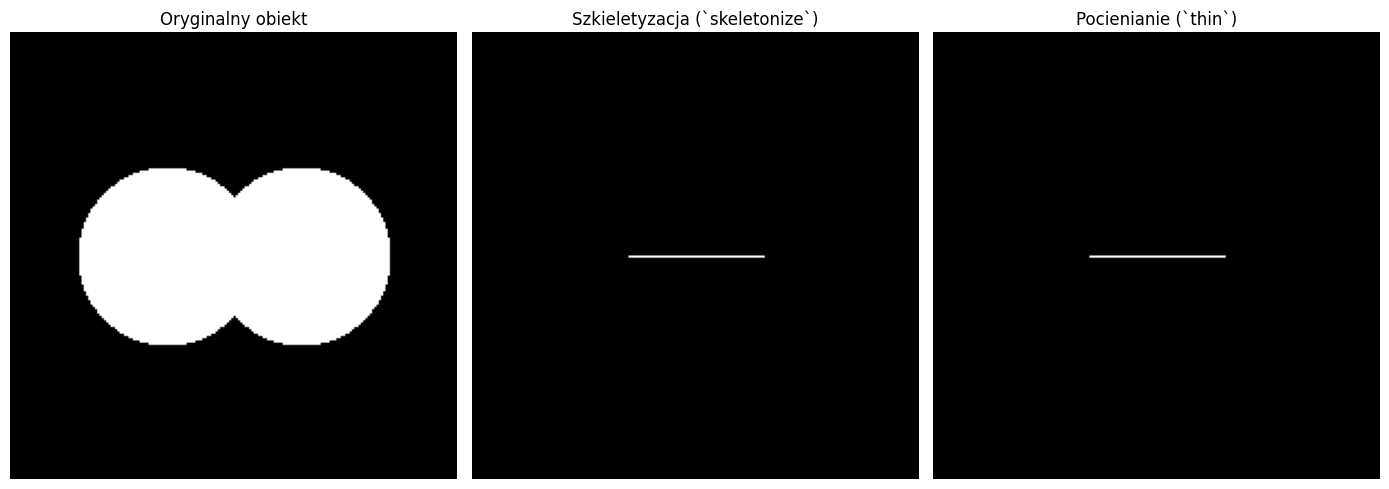

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.morphology import skeletonize, thin
from skimage.draw import disk
from skimage.util import invert

# Utwórz prosty obiekt (np. dwa połączone okręgi)
image = np.zeros((200, 200), dtype=bool)
rr, cc = disk((100, 70), 40)
image[rr, cc] = 1
rr, cc = disk((100, 130), 40)
image[rr, cc] = 1

# Szkieletyzacja i pocienianie
skeleton = skeletonize(image)
thinned = thin(image)

# Wizualizacja
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(image, cmap='gray')
ax[0].set_title("Oryginalny obiekt")

ax[1].imshow(skeleton, cmap='gray')
ax[1].set_title("Szkieletyzacja (`skeletonize`)")

ax[2].imshow(thinned, cmap='gray')
ax[2].set_title("Pocienianie (`thin`)")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

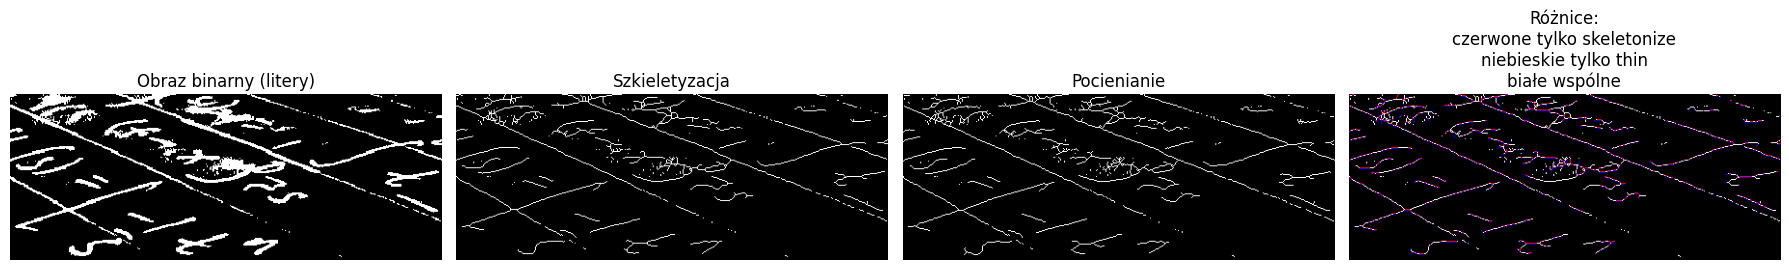

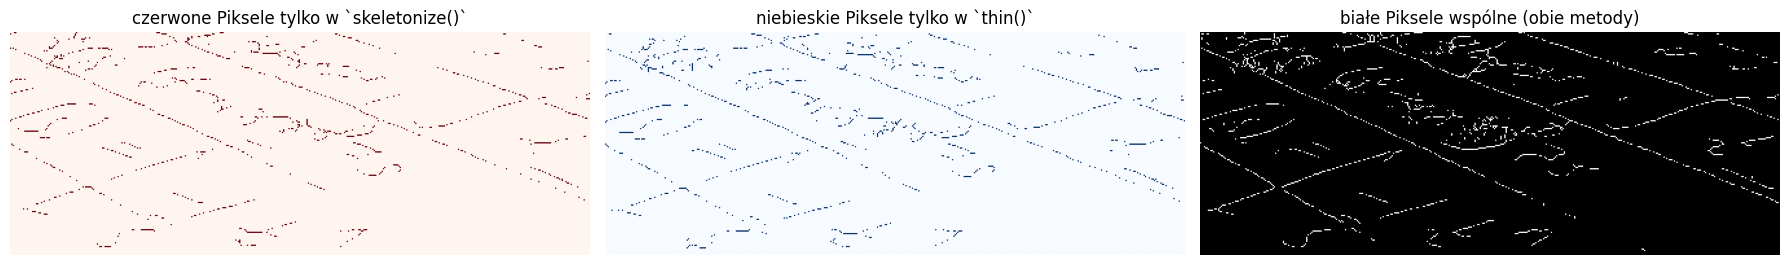

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.filters import threshold_otsu
from skimage.morphology import skeletonize, thin

# Wczytaj obraz tekstu
img = data.text()

# Sprawdź czy RGB czy już 2D
if img.ndim == 3:
    gray = color.rgb2gray(img)
else:
    gray = img.astype(np.float64)
    if gray.max() > 1.0:
        gray /= gray.max()

# Binarizacja
th = threshold_otsu(gray)
binary = gray < th
binary = binary.astype(bool)

# Szkieletyzacja i pocienianie
skel = skeletonize(binary)
thin_img = thin(binary)

# Oblicz różnice
only_skel = np.logical_and(skel, np.logical_not(thin_img))   # czerwone
only_thin = np.logical_and(thin_img, np.logical_not(skel))   # niebieskie
both = np.logical_and(skel, thin_img)                        # wspólne (białe)

# Utwórz kolorowy obraz różnic
diff_rgb = np.zeros((*binary.shape, 3))
diff_rgb[..., 0] = only_skel      # red channel
diff_rgb[..., 2] = only_thin      # blue channel
diff_rgb[..., 0:3] += both[..., None]  # dodaj wspólne (biały)

# --- Główne porównanie (4 obrazy) ---
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(binary, cmap='gray')
ax[0].set_title("Obraz binarny (litery)")

ax[1].imshow(skel, cmap='gray')
ax[1].set_title("Szkieletyzacja")

ax[2].imshow(thin_img, cmap='gray')
ax[2].set_title("Pocienianie")

ax[3].imshow(diff_rgb)
ax[3].set_title("Różnice:\nczerwone tylko skeletonize\nniebieskie tylko thin\nbiałe wspólne")

for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

# --- Dodatkowe trzy obrazy osobno ---
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].imshow(only_skel, cmap='Reds')
ax[0].set_title("czerwone Piksele tylko w `skeletonize()`")

ax[1].imshow(only_thin, cmap='Blues')
ax[1].set_title("niebieskie Piksele tylko w `thin()`")

ax[2].imshow(both, cmap='gray')
ax[2].set_title("białe Piksele wspólne (obie metody)")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

* Czerwony - Piksele obecne tylko w skeletonize - Ta metoda zostawia nieco „grubsze” fragmenty i rozgałęzienia.
* Niebieski	- Piksele obecne tylko w thin	Pocienianie usuwa więcej pikseli – daje cieńszy, jednolity szkielet.
* Biały	- Piksele wspólne	To „rdzeń” kształtu – wspólna oś uznana przez obie metody.

## Przycinanie (z ang. Pruning) to proces usuwania krótkich, nieistotnych gałązek ze szkieletu obiektu binarnego.
Celem tej operacji jest oczyszczenie szkieletu z drobnych odgałęzień, które powstały w wyniku:

* szumów w obrazie,
* niejednorodnego oświetlenia,
* nieidealnej segmentacji lub binarizacji.

Metody przycinania

* Iteracyjne usuwanie końcówek - najprostsza metoda: w każdej iteracji usuwa się piksele końcowe (z jednym sąsiadem). Po kilku iteracjach znikają krótkie odnogi, ale główny kształt zostaje zachowany.

* Pruning oparty na długości gałęzi. Wykrywa wszystkie gałęzie i mierzy ich długość (np. przez przeszukiwanie grafu). Usuwa tylko te, których długość < ustalonego progu (np. 10 pikseli).

* Pruning morfologiczny - Wykorzystuje operacje morfologiczne (np. hit-or-miss) do usuwania specyficznych wzorców końcówek.

C:\Users\pawel\AppData\Local\Temp\ipykernel_13108\2230044110.py:25: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  binary = remove_small_objects(binary, 64)


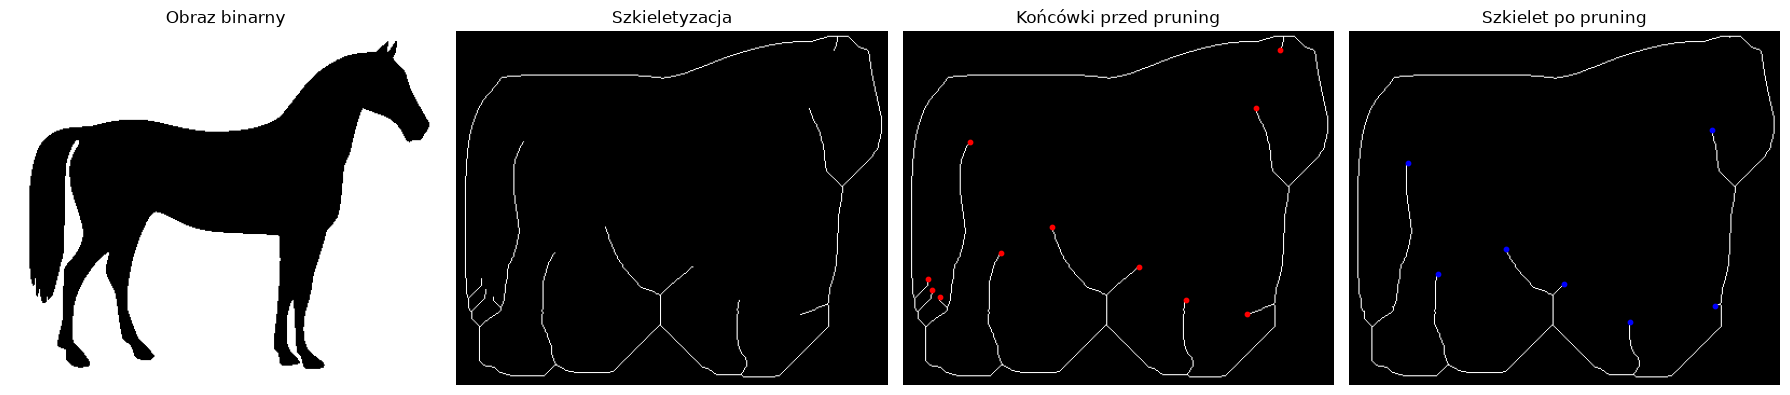

Piksele szkieletu (przed): 1823
Piksele szkieletu (po)   : 1624
Końcówki (przed)         : 11
Końcówki (po)            : 7


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import data, color
from skimage.filters import threshold_otsu
from skimage.morphology import skeletonize, remove_small_objects

# --------- 0) Pomocnicze: bezpieczne przygotowanie obrazu binarnego ---------
def to_binary(img):
    """Zwraca obraz binarny (bool) niezależnie od formatu wejścia."""
    if img.dtype == bool and img.ndim == 2:
        return img
    if img.ndim == 3:   # RGB -> gray
        gray = color.rgb2gray(img)
    else:               # już 2D
        gray = img.astype(float)
        if gray.max() > 1.0:  # unormuj jeśli trzeba
            gray /= gray.max()
    th = threshold_otsu(gray)
    return (gray < th)  # ciemne obiekty = True

# Dane i binarizacja
img = data.horse()              # 2D (często bool)
binary = to_binary(img)
binary = remove_small_objects(binary, 64)

# Szkieletyzacja
skel = skeletonize(binary)

# Końcówki i pruning
def find_endpoints(skel_bool):
    """Zwraca maskę końcówek (pikseli z 1 sąsiadem w 8-sąsiedztwie)."""
    # 10 dla centrum, 1 dla sąsiadów -> 10 + 1 = 11 oznacza końcówkę
    kernel = np.array([[1,1,1],
                       [1,10,1],
                       [1,1,1]])
    conv = convolve(skel_bool.astype(np.uint8), kernel, mode='constant', cval=0)
    return conv == 11

def prune_skeleton(skel_bool, max_len=15):
    """
    Iteracyjnie usuwa końcówki do zadanej długości gałązki (max_len w pikselach).
    Każda iteracja odcina 1 piksel na końcu gałęzi.
    """
    pruned = skel_bool.copy()
    for _ in range(max_len):
        endpoints = find_endpoints(pruned)
        # zatrzymaj, gdy nie ma już krótkich końcówek
        if not endpoints.any():
            break
        pruned = np.logical_and(pruned, ~endpoints)
    return pruned

pruned = prune_skeleton(skel, max_len=20)

# Wizualizacja: oryginał, szkielet, końcówki, pruning
endpoints_before = find_endpoints(skel)
endpoints_after  = find_endpoints(pruned)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(binary, cmap='gray'); ax[0].set_title("Obraz binarny"); ax[0].axis('off')
ax[1].imshow(skel, cmap='gray');   ax[1].set_title("Szkieletyzacja"); ax[1].axis('off')

# nałóż końcówki przed pruning (czerwone)
ax[2].imshow(skel, cmap='gray')
y, x = np.where(endpoints_before)
ax[2].scatter(x, y, s=10, c='r')
ax[2].set_title("Końcówki przed pruning"); ax[2].axis('off')

# szkielet po pruning + końcówki po (niebieskie)
ax[3].imshow(pruned, cmap='gray')
y2, x2 = np.where(endpoints_after)
ax[3].scatter(x2, y2, s=10, c='b')
ax[3].set_title("Szkielet po pruning"); ax[3].axis('off')

plt.tight_layout()
plt.show()

# Prosta statystyka
print("Piksele szkieletu (przed):", int(skel.sum()))
print("Piksele szkieletu (po)   :", int(pruned.sum()))
print("Końcówki (przed)         :", int(endpoints_before.sum()))
print("Końcówki (po)            :", int(endpoints_after.sum()))

# Zadanie 1. Analiza odcisków palców z wykorzystaniem szkieletyzacji

## Cel zadania
Celem jest przygotowanie obrazu odcisku palca, uzyskanie **jednopikselowego szkieletu linii papilarnych** i automatyczne wykrycie charakterystycznych punktów (**minucji**):
- **zakończeń linii** (ridge endings),
- **rozwidleń linii** (bifurcations).

### Etapy
1. Wczytanie obrazu w skali szarości.
2. Poprawa kontrastu (np. CLAHE).
3. Binaryzacja (Odsu, Sauvola).
4. Usunięcie drobnych zakłóceń (morfologia).
5. Szkieletyzacja.
6. Wykrywanie minucji metodą **Crossing Number**.
7. Wizualizacja i interpretacja wyników.

## Skąd pobrać obrazy odcisków palców?


*  NIST Special Database 302: https://www.nist.gov/itl/iad/btg/nist-special-database-302?utm_source=chatgpt.com
*  Tsinghua Simulated Fingerprint Database: https://ivg.au.tsinghua.edu.cn/dataset/TDFD.php


Plik: fingerprint.png | rozmiar: (800, 800)


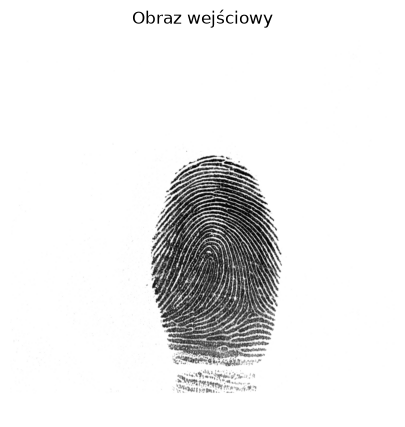

In [21]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import color, exposure, filters, io, morphology, util

# Zmień tę ścieżkę, jeśli dysponujesz obrazem odcisku palca.
IMAGE_PATH = Path("fingerprint.png")


def synthetic_ridges(size=420, seed=12):
    """Syntetyczny obraz z liniami podobnymi do linii papilarnych (tylko demonstracja)."""
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[:size, :size]
    x = (xx - size / 2) / size
    y = (yy - size / 2) / size
    # Nieliniowe, lekko odkształcone linie quasi-koncentryczne.
    r = np.sqrt((x + 0.09 * np.sin(8*y))**2 + (1.17*y)**2 + 1e-6)
    theta = np.arctan2(y, x)
    phase = 2 * np.pi * (31 * r + 0.23*np.sin(3*theta) + 0.05*np.sin(12*x))
    ridge = np.cos(phase) > 0.03
    ellipse = (x / .44)**2 + (y / .47)**2 < 1
    image = np.ones((size, size), dtype=float) * .93
    image[ridge & ellipse] = .22
    image += rng.normal(0, .055, image.shape)
    image = np.clip(image, 0, 1)
    # Białe tło poza obszarem linii.
    image[~ellipse] = 1.0
    return image

def show_comparison(images, titles):
    fig, ax = plt.subplots(1, len(images))
    ax[0].imshow(images[0], cmap='gray')
    ax[0].set_title(titles[0])
    ax[1].imshow(images[1], cmap='gray')
    ax[1].set_title(titles[1])

    for a in ax:
        a.axis("off")
    
    plt.tight_layout()
    plt.show()


if IMAGE_PATH.is_file():
    raw = io.imread(IMAGE_PATH)
    if raw.ndim == 3:
        raw = color.rgb2gray(raw[..., :3])
    gray = util.img_as_float(raw)
    gray = exposure.rescale_intensity(gray, out_range=(0.0, 1.0))
    source = f"Plik: {IMAGE_PATH}"
else:
    gray = synthetic_ridges()
    source = "Przykład syntetyczny (brak fingerprint.png)"

print(source, '| rozmiar:', gray.shape)
plt.figure(figsize=(5, 5))
plt.imshow(gray, cmap='gray', vmin=0, vmax=1)
plt.title('Obraz wejściowy')
plt.axis('off');

## 1. Przygotowanie obrazu i binaryzacja

W odciskach o **ciemnych liniach na jasnym tle** linie papilarne powinny otrzymać wartość `True` (1) w obrazie binarnym. CLAHE poprawia kontrast lokalny, a próg Sauvoli dostosowuje się do jasności otoczenia. Maska obszaru zainteresowania (ROI) ogranicza analizę do rejonu zawierającego linie.
Oczyszczanie obrazu – usuń drobne zakłócenia i wypełnij niewielkie otwory

**Uwaga:** W rzeczywistych obrazach odcisków palców jakość segmentacji obszaru zainteresowania bywa trudna i wymaga dostrojenia parametrów.




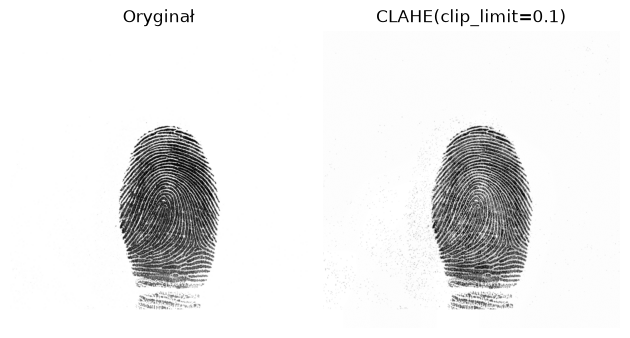

In [23]:
clahe_equalized = exposure.equalize_adapthist(gray, clip_limit=0.1)
show_comparison([gray, clahe_equalized], ["Oryginał", "CLAHE(clip_limit=0.1)"])

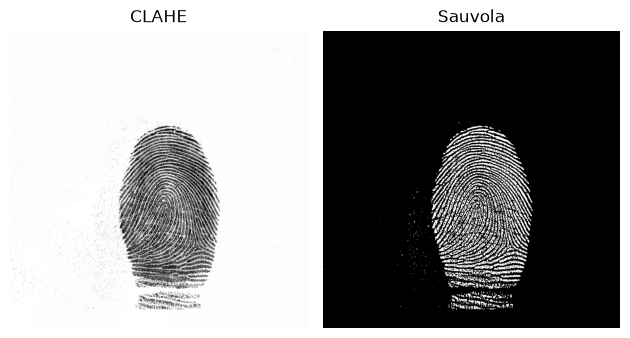

In [27]:
binary = util.invert(clahe_equalized > filters.threshold_sauvola(clahe_equalized))

show_comparison([clahe_equalized, binary], ["CLAHE", "Sauvola"])

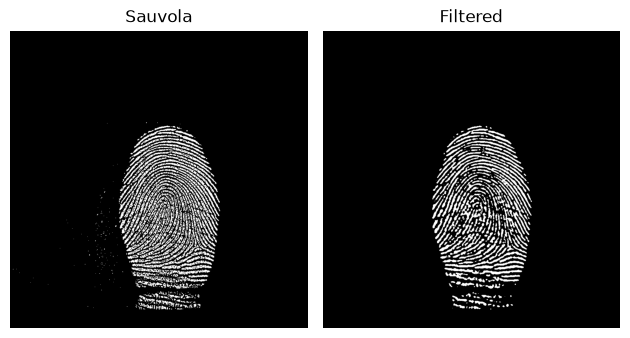

In [31]:
neighborhood = morphology.disk(
    radius=3
)
filtered = filters.median(binary, neighborhood)
show_comparison([binary, filtered], ["Sauvola", "Filtered"])

## 2. Szkieletyzacja

Szkieletyzacja redukuje grubość linii do około jednego piksela. Dzięki temu można analizować topologię linii i policzyć przejścia między pikselami w sąsiedztwie 8-kierunkowym.

## 3. Wykrywanie minucji – Crossing Number

Dla każdego piksela szkieletu liczymy liczbę zmian wartości w cyklicznym otoczeniu 8 sąsiadów:

$$CN = \frac{1}{2}\sum_{i=1}^{8}|P_i-P_{i+1}|,\qquad P_9=P_1.$$

Interpretacja (dla poprawnie wyznaczonego, jednopikselowego szkieletu):
- `CN = 1` – zakończenie linii,
- `CN = 2` – punkt ciągłej linii,
- `CN = 3` – rozwidlenie.

Punkty wykryte przy brzegu obszaru zainteresowania często nie są rzeczywistymi minucjami. Dlatego wykluczamy je i grupujemy sąsiadujące wykrycia. Wynik jest **heurystyczny**, nie stanowi gotowego systemu identyfikacji biometrycznej.

## 4. Zadania do wykonania przez studentów

1. **Wykonaj cały algorytm** dla obrazu testowego i zapisz wizualizacje etapów (Obraz oryginalny, Obraz po poprawie kontrastu, Obraz po binaryzacji, Obraz po operacjach morfologicznych, Obraz po szkieletyzacji, Szkielet z zaznaczonymi zakończeniami, rozwidleniami linii, minucjami)
2. **Zmień parametr** `SAUVOLA_WINDOW` na 15, 25 i 41. Porównaj otrzymane szkielety i liczby minucji.
3. **Zmień** `MIN_OBJECT_SIZE` na 10, 22 i 50. Sprawdź, czy zmienia się liczba fałszywych zakończeń.
4. Wczytaj **inny obraz odcisku palca** i oceń jakość działania algorytmu.
5. Wskaż na obrazie co najmniej **dwa błędnie wykryte punkty** i wyjaśnij, skąd się wzięły (jeśli błędów nie ma, opisz mechanizm ich powstawania).



**Rozszerzenie zadania **– porównanie dwóch odcisków palców
To może być szczególnie interesujący element laboratorium.

Studenci otrzymują trzy obrazy:
- Obraz A – odcisk pierwszego palca.
- Obraz B – drugi odcisk tego samego palca.
- Obraz C – odcisk innego palca.
Ich zadaniem jest przeprowadzenie szkieletyzacji, wykrycie minucji i porównanie rozmieszczenia charakterystycznych punktów.

W tym wariancie należy uwzględnić również przesunięcie i obrót obrazów, ponieważ odciski tego samego palca nie muszą być identycznie ułożone.

# Zadanie dla chetnych. Analiza układu naczyń krwionośnych (lub dróg) z wykorzystaniem szkieletyzacji

Cel:
Zastosować szkieletyzację do analizy i modelowania rozgałęzionej struktury obiektów — takich jak naczynia krwionośne, korzenie roślin, sieci drogowe lub linie pisma.
Celem jest uzyskanie uproszczonej reprezentacji struktury (szkieletu), która zachowuje topologię, umożliwia pomiar długości i rozgałęzień.

Wyobraź sobie, że jesteś inżynierem biomedycznym analizującym zdjęcia mikroskopowe naczyń krwionośnych. Obraz jest binarny (ciemne naczynia na jasnym tle). Chcesz automatycznie:

* uzyskać szkielet naczyń,
* obliczyć łączną długość naczyń,
* określić liczbę rozgałęzień i końcówek.

Podobne podejście można wykorzystać np. w analizie:

* sieci dróg z obrazów satelitarnych,
* struktur roślinnych (korzeni, liści),
* połączeń ścieżek w układach scalonych.


# Kolejne kroki

Wczytaj obraz (np. mikroskopowy obraz naczyń lub sieć dróg — można użyć data.retina() lub własnego zdjęcia).
Jeśli obraz jest kolorowy — przekształć go do skali szarości.

1. Wykonaj progowanie (np. metodą Otsu), aby uzyskać obraz binarny przedstawiający strukturę obiektu.

2. Wyczyść obraz – usuń małe obiekty i zakłócenia (remove_small_objects, closing, opening).

3. Zastosuj szkieletyzację (skeletonize) do uzyskania osi struktur.

4. Oblicz cechy geometryczne:

* liczbę końcówek szkieletu (punkty z jednym sąsiadem),
* liczbę rozgałęzień (punkty z więcej niż dwoma sąsiadami).

Koncepcja cech geometrycznych szkieletu:
Każdy piksel w szkielecie ma pewną liczbę sąsiadów (8-sąsiedztwo):
* Końcówka (endpoint): piksel, który ma dokładnie jednego sąsiada.
→ Jest to koniec gałęzi szkieletu.
* Rozgałęzienie (branch point): piksel, który ma więcej niż dwóch sąsiadów.→ W tym miejscu łączą się lub rozdzielają gałęzie struktury.

Wizualizuj wynik:

* oryginalny obraz,
* obraz binarny,
* szkielet